<a href="https://colab.research.google.com/github/GiulioGalatro/lox-ch4-rocket-model/blob/main/rocketmodel0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== LOX/CH4 ENGINE OPTIMIZATION RESULTS ===
Optimal O/F Ratio: 3.60
Maximum Specific Impulse (Isp): 294.59 s
Generated Thrust: 43.33 kN
Chamber Temperature (Tc): 3618.2 K
Oxidizer Flow Rate (LOX): 11.74 kg/s
Fuel Flow Rate (CH4): 3.26 kg/s


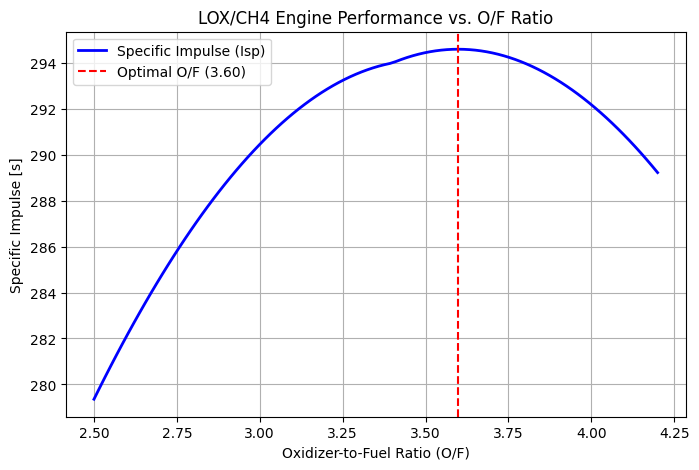

In [3]:
import numpy as np
import matplotlib.pyplot as plt

class LOXCH4EngineModel:
    """
    Thermodynamic and aerothermochemical model for a liquid rocket engine
    using Liquid Oxygen (LOX) and Methane (CH4).
    """
    def __init__(self, pc, pe, pa, at, expansion_ratio, mdot_total):
        """
        Initializes geometric and operational parameters of the rocket engine.
        :param pc: Chamber pressure [Pa]
        :param pe: Nozzle exit pressure [Pa]
        :param pa: Ambient pressure [Pa] (e.g., 101325 for sea level, 0 for vacuum)
        :param at: Nozzle throat area [m^2]
        :param expansion_ratio: Nozzle expansion ratio (Ae / At)
        :param mdot_total: Total propellant mass flow rate [kg/s]
        """
        self.pc = pc
        self.pe = pe
        self.pa = pa
        self.At = at
        self.eps = expansion_ratio
        self.mdot = mdot_total

    def lox_ch4_properties(self, of_ratio):
        """
        Empirical estimation based on NASA CEA (Chemical Equilibrium with Applications)
        data for high-pressure LOX/CH4 (approx. 5-10 MPa).
        Returns: Chamber Temperature [K], Molecular Weight [g/mol], Gamma (cp/cv).
        """
        # Flame temperature peaks near stoichiometry (~3.99)
        tc = 3620 - 180 * (of_ratio - 3.7)**2

        # Molecular weight increases as oxidizer ratio increases
        mw = 22.5 + 1.2 * (of_ratio - 3.4)**2

        # Ratio of specific heats (gamma) typically ranges between 1.13 and 1.17
        gamma = 1.16 - 0.008 * abs(of_ratio - 3.4)

        return tc, mw, gamma

    def calculate_performance(self, of_ratio):
        """Calculates thrust, characteristic velocity (c*), thrust coefficient (Cf), and Isp for a given O/F ratio."""
        R_universal = 8314.46  # J / (kmol K)
        tc, mw, gamma = self.lox_ch4_properties(of_ratio)
        R_specific = R_universal / mw  # J / (kg K)

        # Gamma function for characteristic velocity c* calculation
        gamma_func = np.sqrt(gamma) * (2.0 / (gamma + 1.0)) ** ((gamma + 1.0) / (2.0 * (gamma - 1.0)))
        c_star = np.sqrt(R_specific * tc) / gamma_func

        # Thrust coefficient (Cf)
        pr = self.pe / self.pc
        term1 = (2.0 * gamma**2 / (gamma - 1.0)) * (2.0 / (gamma + 1.0)) ** ((gamma + 1.0) / (gamma - 1.0))
        term2 = 1.0 - (pr) ** ((gamma - 1.0) / gamma)

        cf = np.sqrt(term1 * term2) + (self.pe - self.pa) / self.pc * self.eps

        # Total thrust [N]
        thrust = self.mdot * c_star * cf

        # Specific Impulse [s]
        g0 = 9.80665
        isp = thrust / (self.mdot * g0)

        # Propellant mass flow breakdown
        mdot_fuel = self.mdot / (of_ratio + 1.0)
        mdot_ox = self.mdot * of_ratio / (of_ratio + 1.0)

        return {
            "of_ratio": of_ratio,
            "Tc": tc,
            "Isp_s": isp,
            "Thrust_N": thrust,
            "c_star": c_star,
            "Cf": cf,
            "mdot_ox": mdot_ox,
            "mdot_fuel": mdot_fuel
        }

    def optimize_of(self, of_min=2.5, of_max=4.2, steps=100):
        """Finds the O/F ratio that maximizes Specific Impulse (Isp)."""
        of_range = np.linspace(of_min, of_max, steps)
        best_isp = 0
        best_result = None

        for of in of_range:
            res = self.calculate_performance(of)
            if res["Isp_s"] > best_isp:
                best_isp = res["Isp_s"]
                best_result = res

        return best_result, of_range

# --- Usage Example ---
if __name__ == "__main__":
    # Configuration of a medium-thrust demonstration engine
    engine = LOXCH4EngineModel(
        pc=6.0e6,             # Chamber pressure: 6 MPa (60 bar)
        pe=101325,            # Exit pressure: 1 atm (optimized for sea level)
        pa=101325,            # Ambient pressure: 1 atm
        at=0.005,             # Throat area: 0.005 m^2 (50 cm^2)
        expansion_ratio=12.0, # Nozzle expansion ratio Ae/At
        mdot_total=15.0       # Total mass flow rate: 15 kg/s
    )

    optimal, of_range = engine.optimize_of()
    isp_values = [engine.calculate_performance(of)["Isp_s"] for of in of_range]

    print("=== LOX/CH4 ENGINE OPTIMIZATION RESULTS ===")
    print(f"Optimal O/F Ratio: {optimal['of_ratio']:.2f}")
    print(f"Maximum Specific Impulse (Isp): {optimal['Isp_s']:.2f} s")
    print(f"Generated Thrust: {optimal['Thrust_N'] / 1000:.2f} kN")
    print(f"Chamber Temperature (Tc): {optimal['Tc']:.1f} K")
    print(f"Oxidizer Flow Rate (LOX): {optimal['mdot_ox']:.2f} kg/s")
    print(f"Fuel Flow Rate (CH4): {optimal['mdot_fuel']:.2f} kg/s")

    # Plotting results with Matplotlib
    plt.figure(figsize=(8, 5))
    plt.plot(of_range, isp_values, label='Specific Impulse (Isp)', color='b', linewidth=2)
    plt.axvline(optimal['of_ratio'], color='r', linestyle='--', label=f"Optimal O/F ({optimal['of_ratio']:.2f})")
    plt.title("LOX/CH4 Engine Performance vs. O/F Ratio")
    plt.xlabel("Oxidizer-to-Fuel Ratio (O/F)")
    plt.ylabel("Specific Impulse [s]")
    plt.grid(True)
    plt.legend()
    plt.show()